##### Libraries

In [23]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV, GridSearchCV,
                                     cross_val_score, learning_curve, validation_curve)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
                             average_precision_score)
 
RANDOM_STATE = 42
os.makedirs("outputs/rf", exist_ok=True)
sns.set_style("whitegrid")

##### Load the Data

In [2]:
X_train = pd.read_csv("Data/X_train.csv")
X_test = pd.read_csv("Data/X_test.csv")
y_train = pd.read_csv("Data/y_train.csv").squeeze()
y_test = pd.read_csv("Data/y_test.csv").squeeze()
 
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 3), "| Test churn rate:", round(y_test.mean(), 3))

X_train: (5634, 22) | X_test: (1409, 22)
Train churn rate: 0.265 | Test churn rate: 0.265


##### Created a Evaluator Function

In [3]:
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, threshold=0.5):
    proba_te = model.predict_proba(X_te)[:, 1]
    pred_te = (proba_te >= threshold).astype(int)
    pred_tr = (model.predict_proba(X_tr)[:, 1] >= threshold).astype(int)
    return {
        "Model": name,
        "Train Accuracy": accuracy_score(y_tr, pred_tr),
        "Test Accuracy": accuracy_score(y_te, pred_te),
        "Precision": precision_score(y_te, pred_te),
        "Recall": recall_score(y_te, pred_te),
        "F1-Score": f1_score(y_te, pred_te),
        "ROC-AUC": roc_auc_score(y_te, proba_te),
        "PR-AUC": average_precision_score(y_te, proba_te),
    }

##### Baseline Model

In [4]:
rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)
base_results = evaluate_model("RF Baseline", rf_base, X_train, y_train, X_test, y_test)
print("\nBaseline Random Forest - Classification Report")
print(classification_report(y_test, rf_base.predict(X_test), target_names=["No Churn", "Churn"]))


Baseline Random Forest - Classification Report
              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.63      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



##### 5-fold Cross Validation

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_cv = cross_val_score(rf_base, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
print(f"Baseline 5-fold CV F1: {base_cv.mean():.4f} ± {base_cv.std():.4f}")

Baseline 5-fold CV F1: 0.5512 ± 0.0107


##### Hyperparameter Tuning - RandomizedSearchCV

In [6]:
param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 5, 8, 10, 12, 15, 20],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": ["sqrt", "log2", 0.5],
    "bootstrap": [True, False],
    "class_weight": [None, "balanced", "balanced_subsample"],
}
random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist, n_iter=40, cv=cv,
    scoring={"f1": "f1", "roc_auc": "roc_auc", "recall": "recall", "accuracy": "accuracy"},
    refit="f1", random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
random_search.fit(X_train, y_train)
print("Best params (random):", random_search.best_params_)
print(f"Best CV F1 (random): {random_search.best_score_:.4f}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best params (random): {'n_estimators': 100, 'min_samples_split': 20, 'min_samples_leaf': 8, 'max_features': 'log2', 'max_depth': 15, 'class_weight': 'balanced_subsample', 'bootstrap': True}
Best CV F1 (random): 0.6382


##### Top 10 parameters from RandomizedSearchCV

In [7]:
cv_res = pd.DataFrame(random_search.cv_results_).sort_values("rank_test_f1").head(10).reset_index(drop=True)

params_df = pd.DataFrame([{k: str(v) for k, v in p.items()} for p in cv_res["params"]])
params_df = params_df[["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf",
                       "max_features", "bootstrap", "class_weight"]]

scores_df = cv_res[["mean_test_f1", "std_test_f1", "mean_test_roc_auc",
                    "mean_test_recall", "mean_test_accuracy"]].round(4)
scores_df.columns = ["Mean F1", "Std F1", "ROC-AUC", "Recall", "Accuracy"]

top10 = pd.concat([params_df, scores_df], axis=1)
top10.insert(0, "Rank", range(1, len(top10) + 1))

print("Top 10 RandomizedSearchCV results:")
display(top10.style.hide(axis="index")
        .format(precision=4, subset=["Mean F1", "Std F1", "ROC-AUC", "Recall", "Accuracy"])
        .highlight_max(subset=["Mean F1", "ROC-AUC", "Recall", "Accuracy"], color="#cfe2f3"))

top10.to_csv("outputs/rf/rf_random_search_top10.csv", index=False)

Top 10 RandomizedSearchCV results:


Rank,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,class_weight,Mean F1,Std F1,ROC-AUC,Recall,Accuracy
1,100,15,20,8,log2,True,balanced_subsample,0.6382,0.0190,0.8440,0.7625,0.7707
2,500,8,2,4,log2,True,balanced_subsample,0.6365,0.0147,0.8464,0.7659,0.7678
3,100,10,5,8,0.5,True,balanced_subsample,0.6365,0.0181,0.8430,0.7431,0.7748
4,100,8,5,2,sqrt,True,balanced_subsample,0.6362,0.0178,0.8454,0.7612,0.7689
5,500,5,5,4,sqrt,True,balanced_subsample,0.6358,0.0179,0.8464,0.8134,0.7526
6,200,10,10,8,log2,True,balanced_subsample,0.6353,0.0175,0.8453,0.7605,0.7684
7,200,12,10,8,log2,False,balanced,0.6351,0.0178,0.8438,0.7652,0.7666
8,500,5,10,4,sqrt,False,balanced,0.6347,0.0166,0.8461,0.8147,0.7510
9,300,5,10,1,sqrt,False,balanced,0.6343,0.0169,0.8460,0.8114,0.7515
10,200,12,20,2,log2,False,balanced_subsample,0.6338,0.0174,0.8420,0.7498,0.7701


##### Hyperparameter Tuning - GridSearchCV

In [8]:
bp = random_search.best_params_
param_grid = {
    "n_estimators": sorted({max(100, bp["n_estimators"] - 100), bp["n_estimators"], bp["n_estimators"] + 100}),
    "max_depth": [None] if bp["max_depth"] is None else sorted({max(3, bp["max_depth"] - 2), bp["max_depth"], bp["max_depth"] + 2}),
    "min_samples_leaf": sorted({max(1, bp["min_samples_leaf"] // 2), bp["min_samples_leaf"], bp["min_samples_leaf"] * 2}),
    "min_samples_split": [bp["min_samples_split"]],
    "max_features": [bp["max_features"]],
    "bootstrap": [bp["bootstrap"]],
    "class_weight": [bp["class_weight"]],
}
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid, cv=cv, scoring="f1", n_jobs=-1, verbose=1,
)
grid_search.fit(X_train, y_train)
print("Best params (grid):", grid_search.best_params_)
print(f"Best CV F1 (grid): {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best params (grid): {'bootstrap': True, 'class_weight': 'balanced_subsample', 'max_depth': 13, 'max_features': 'log2', 'min_samples_leaf': 8, 'min_samples_split': 20, 'n_estimators': 200}
Best CV F1 (grid): 0.6383


##### Tuned Random Forest model

In [9]:
rf_tuned = grid_search.best_estimator_
tuned_results = evaluate_model("RF Tuned", rf_tuned, X_train, y_train, X_test, y_test)
print("\nTuned Random Forest - Classification Report")
print(classification_report(y_test, rf_tuned.predict(X_test), target_names=["No Churn", "Churn"]))


Tuned Random Forest - Classification Report
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83      1035
       Churn       0.55      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409



##### Hyperparameters table (default vs tuned)

In [10]:
default_params = rf_base.get_params()
params_table = pd.DataFrame({
    "Hyperparameter": list(grid_search.best_params_.keys()),
    "Default": [default_params[k] for k in grid_search.best_params_],
    "Tuned": list(grid_search.best_params_.values()),
})
print("\nHyperparameters: Default vs Tuned")
print(params_table.to_string(index=False))
params_table.to_csv("outputs/rf/rf_best_params.csv", index=False)


Hyperparameters: Default vs Tuned
   Hyperparameter Default              Tuned
        bootstrap    True               True
     class_weight    None balanced_subsample
        max_depth    None                 13
     max_features    sqrt               log2
 min_samples_leaf       1                  8
min_samples_split       2                 20
     n_estimators     100                200


##### Metrics comparison table (baseline vs tuned)

In [11]:
comparison = pd.DataFrame([base_results, tuned_results]).set_index("Model").round(4)
print("\nModel Comparison:")
print(comparison.T)
comparison.to_csv("outputs/rf/rf_metrics_comparison.csv")


Model Comparison:
Model           RF Baseline  RF Tuned
Train Accuracy       0.9977    0.8147
Test Accuracy        0.7864    0.7686
Precision            0.6197    0.5455
Recall               0.5053    0.7701
F1-Score             0.5567    0.6386
ROC-AUC              0.8215    0.8464
PR-AUC               0.6156    0.6599


##### Metrics comparison bar chart

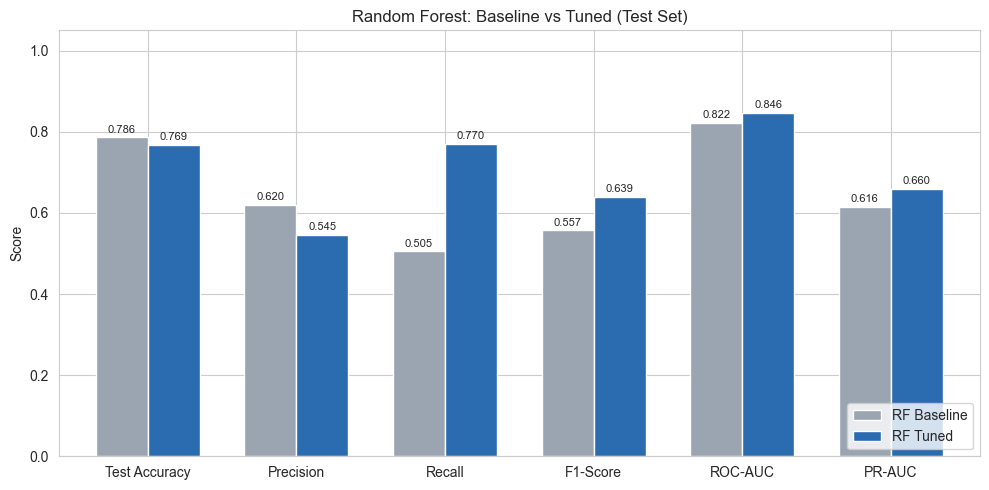

In [12]:
metrics = ["Test Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]
ax = comparison[metrics].T.plot(kind="bar", figsize=(10, 5), color=["#9aa5b1", "#2b6cb0"], width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
plt.title("Random Forest: Baseline vs Tuned (Test Set)")
plt.ylabel("Score"); plt.ylim(0, 1.05); plt.xticks(rotation=0); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("outputs/rf/rf_metrics_comparison.png", dpi=150); plt.show()

##### Confusion matrices side by side

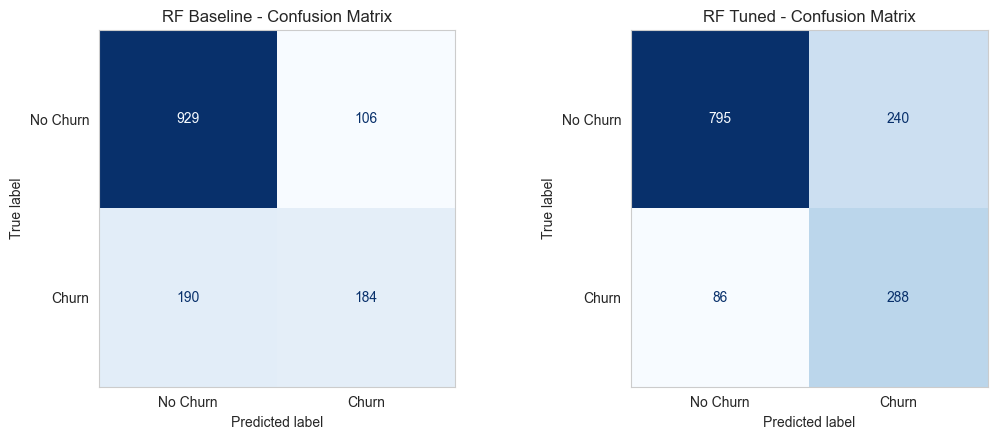

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [("Baseline", rf_base), ("Tuned", rf_tuned)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=["No Churn", "Churn"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"RF {name} - Confusion Matrix")
    ax.grid(False)
plt.tight_layout(); plt.savefig("outputs/rf/rf_confusion_matrices.png", dpi=150); plt.show()

##### ROC curve comparison

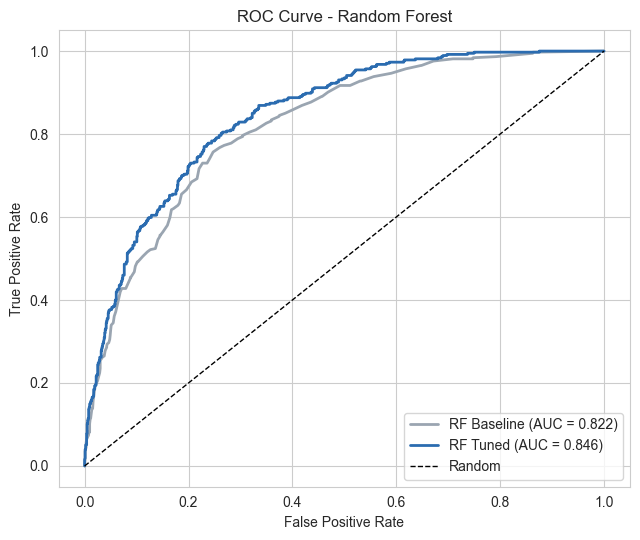

In [14]:
plt.figure(figsize=(6.5, 5.5))
for name, model, col in [("Baseline", rf_base, "#9aa5b1"), ("Tuned", rf_tuned, "#2b6cb0")]:
    p = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, color=col, lw=2, label=f"RF {name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("outputs/rf/rf_roc_curve.png", dpi=150); plt.show()

##### Precision-Recall curve comparison

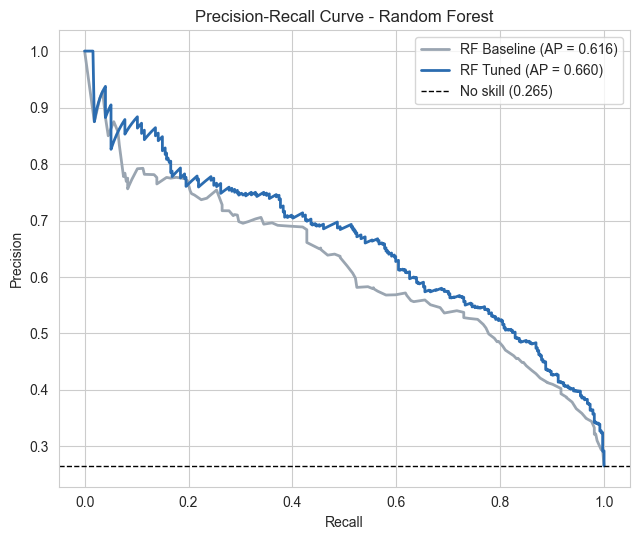

In [15]:
plt.figure(figsize=(6.5, 5.5))
for name, model, col in [("Baseline", rf_base, "#9aa5b1"), ("Tuned", rf_tuned, "#2b6cb0")]:
    p = model.predict_proba(X_test)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, color=col, lw=2, label=f"RF {name} (AP = {average_precision_score(y_test, p):.3f})")
plt.axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"No skill ({y_test.mean():.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Random Forest"); plt.legend(loc="upper right")
plt.tight_layout(); plt.savefig("outputs/rf/rf_pr_curve.png", dpi=150); plt.show()

##### Feature importance


Feature Importance (Tuned RF):
                                Feature  Importance
0                              Contract      0.2101
1                                tenure      0.1607
2                      TotalCharges_log      0.1143
3           InternetService_Fiber_optic      0.0947
4        PaymentMethod_Electronic_check      0.0744
5                    InternetService_No      0.0647
6                         charge_change      0.0604
7                        has_protection      0.0323
8                      PaperlessBilling      0.0270
9                        OnlineSecurity      0.0197
10                          TechSupport      0.0160
11                      StreamingMovies      0.0157
12                           Dependents      0.0143
13                          StreamingTV      0.0138
14                         OnlineBackup      0.0129
15                        MultipleLines      0.0129
16                              Partner      0.0108
17                             i

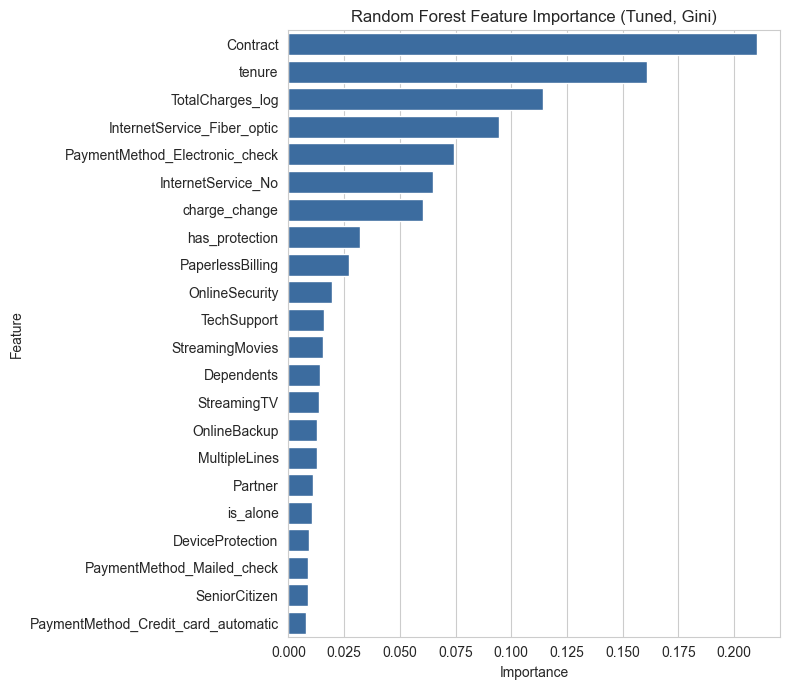

In [16]:
importance = (pd.DataFrame({"Feature": X_train.columns, "Importance": rf_tuned.feature_importances_})
              .sort_values("Importance", ascending=False).reset_index(drop=True))
print("\nFeature Importance (Tuned RF):")
print(importance.round(4).to_string())
importance.to_csv("outputs/rf/rf_feature_importance.csv", index=False)

plt.figure(figsize=(8, 7))
sns.barplot(data=importance, y="Feature", x="Importance", color="#2b6cb0")
plt.title("Random Forest Feature Importance (Tuned, Gini)")
plt.tight_layout(); plt.savefig("outputs/rf/rf_feature_importance.png", dpi=150); plt.show()

##### Overfitting check

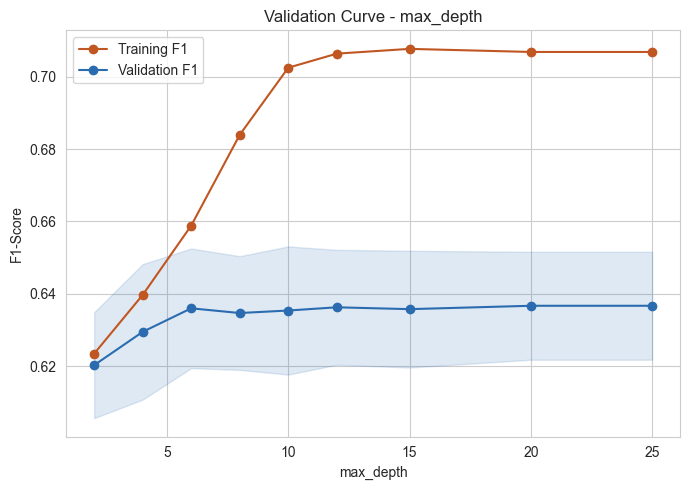

In [17]:
tuned_params = rf_tuned.get_params()
depths = [2, 4, 6, 8, 10, 12, 15, 20, 25]
vc_model = RandomForestClassifier(**{**tuned_params, "max_depth": None})
tr_sc, va_sc = validation_curve(vc_model, X_train, y_train, param_name="max_depth",
                                param_range=depths, cv=cv, scoring="f1", n_jobs=-1)
plt.figure(figsize=(7, 5))
plt.plot(depths, tr_sc.mean(1), "o-", color="#c05621", label="Training F1")
plt.plot(depths, va_sc.mean(1), "o-", color="#2b6cb0", label="Validation F1")
plt.fill_between(depths, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color="#2b6cb0", alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("F1-Score"); plt.title("Validation Curve - max_depth")
plt.legend(); plt.tight_layout(); plt.savefig("outputs/rf/rf_validation_curve_depth.png", dpi=150); plt.show()

##### Validation curve for n_estimators

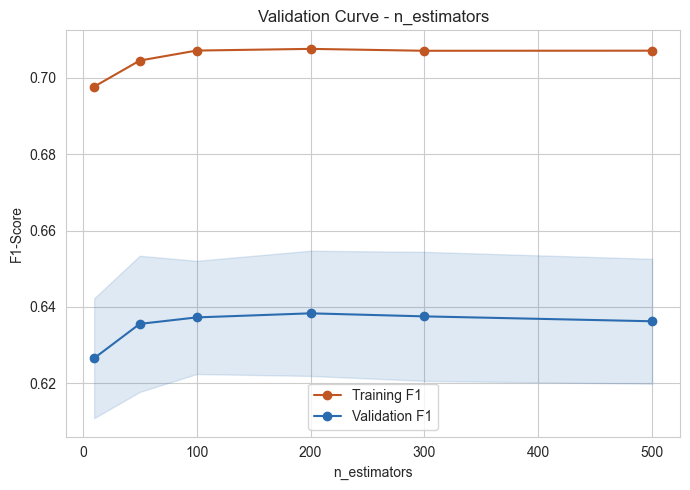

In [18]:
n_trees = [10, 50, 100, 200, 300, 500]
tr_sc, va_sc = validation_curve(RandomForestClassifier(**tuned_params), X_train, y_train,
                                param_name="n_estimators", param_range=n_trees,
                                cv=cv, scoring="f1", n_jobs=-1)
plt.figure(figsize=(7, 5))
plt.plot(n_trees, tr_sc.mean(1), "o-", color="#c05621", label="Training F1")
plt.plot(n_trees, va_sc.mean(1), "o-", color="#2b6cb0", label="Validation F1")
plt.fill_between(n_trees, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color="#2b6cb0", alpha=0.15)
plt.xlabel("n_estimators"); plt.ylabel("F1-Score"); plt.title("Validation Curve - n_estimators")
plt.legend(); plt.tight_layout(); plt.savefig("outputs/rf/rf_validation_curve_trees.png", dpi=150); plt.show()

##### Learning curves (baseline vs tuned)

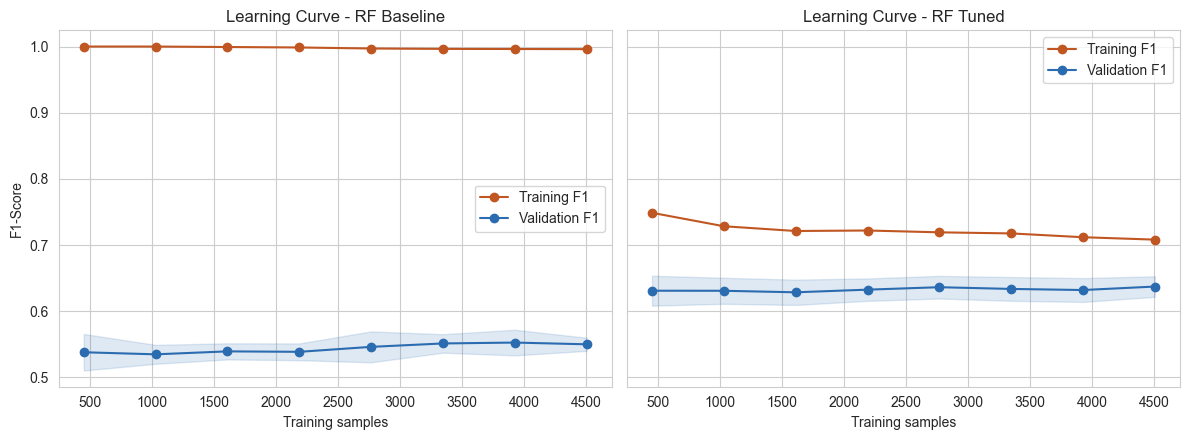

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (name, model) in zip(axes, [("Baseline", rf_base), ("Tuned", rf_tuned)]):
    sizes, tr_sc, va_sc = learning_curve(model, X_train, y_train, cv=cv, scoring="f1",
                                         train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1)
    ax.plot(sizes, tr_sc.mean(1), "o-", color="#c05621", label="Training F1")
    ax.plot(sizes, va_sc.mean(1), "o-", color="#2b6cb0", label="Validation F1")
    ax.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color="#2b6cb0", alpha=0.15)
    ax.set_title(f"Learning Curve - RF {name}"); ax.set_xlabel("Training samples"); ax.legend()
axes[0].set_ylabel("F1-Score")
plt.tight_layout(); plt.savefig("outputs/rf/rf_learning_curves.png", dpi=150); plt.show()

##### Decision threshold analysis


Threshold analysis (Tuned RF):
 Threshold  Accuracy  Precision  Recall  F1-Score
      0.20    0.5848     0.3862  0.9572    0.5503
      0.25    0.6309     0.4127  0.9225    0.5702
      0.30    0.6615     0.4334  0.8957    0.5841
      0.35    0.6991     0.4645  0.8743    0.6067
      0.40    0.7268     0.4914  0.8369    0.6192
      0.45    0.7530     0.5226  0.8021    0.6329
      0.50    0.7686     0.5455  0.7701    0.6386
      0.55    0.7771     0.5644  0.7032    0.6262
      0.60    0.7906     0.5990  0.6390    0.6184
      0.65    0.8027     0.6404  0.5856    0.6117
      0.70    0.8048     0.6840  0.4920    0.5723
      0.75    0.7963     0.7164  0.3850    0.5009
      0.80    0.7807     0.7481  0.2620    0.3881


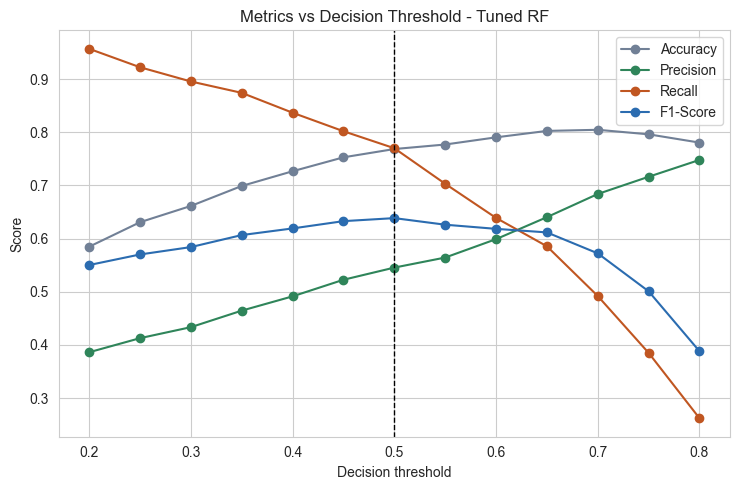

In [20]:
proba = rf_tuned.predict_proba(X_test)[:, 1]
thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
thr_table = pd.DataFrame([{
    "Threshold": t,
    "Accuracy": accuracy_score(y_test, proba >= t),
    "Precision": precision_score(y_test, proba >= t, zero_division=0),
    "Recall": recall_score(y_test, proba >= t),
    "F1-Score": f1_score(y_test, proba >= t),
} for t in thresholds]).round(4)
print("\nThreshold analysis (Tuned RF):")
print(thr_table.to_string(index=False))
thr_table.to_csv("outputs/rf/rf_threshold_analysis.csv", index=False)

plt.figure(figsize=(7.5, 5))
for col, c in zip(["Accuracy", "Precision", "Recall", "F1-Score"], ["#718096", "#2f855a", "#c05621", "#2b6cb0"]):
    plt.plot(thr_table["Threshold"], thr_table[col], "o-", color=c, label=col)
plt.axvline(0.5, color="k", ls="--", lw=1)
plt.xlabel("Decision threshold"); plt.ylabel("Score"); plt.title("Metrics vs Decision Threshold - Tuned RF")
plt.legend(); plt.tight_layout(); plt.savefig("outputs/rf/rf_threshold_analysis.png", dpi=150); plt.show()

##### Cross-validation score comparison


5-Fold CV F1 scores:
        RF Baseline  RF Tuned
Fold 1       0.5468    0.6416
Fold 2       0.5438    0.6093
Fold 3       0.5665    0.6335
Fold 4       0.5382    0.6520
Fold 5       0.5608    0.6552
Mean         0.5512    0.6383
Std          0.0120    0.0183


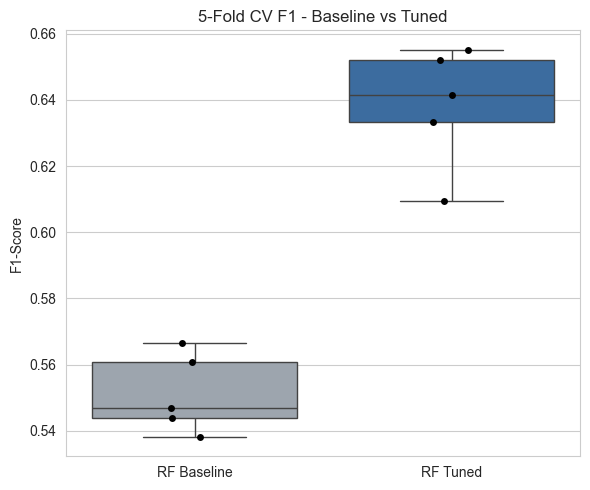

In [21]:
cv_scores = {}
for name, model in [("RF Baseline", rf_base), ("RF Tuned", rf_tuned)]:
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
cv_table = pd.DataFrame(cv_scores, index=[f"Fold {i+1}" for i in range(5)])
cv_table.loc["Mean"] = cv_table.mean(); cv_table.loc["Std"] = cv_table.iloc[:5].std()
print("\n5-Fold CV F1 scores:")
print(cv_table.round(4))
cv_table.to_csv("outputs/rf/rf_cv_scores.csv")

plt.figure(figsize=(6, 5))
sns.boxplot(data=pd.DataFrame(cv_scores), palette=["#9aa5b1", "#2b6cb0"])
sns.stripplot(data=pd.DataFrame(cv_scores), color="k", size=5)
plt.ylabel("F1-Score"); plt.title("5-Fold CV F1 - Baseline vs Tuned")
plt.tight_layout(); plt.savefig("outputs/rf/rf_cv_boxplot.png", dpi=150); plt.show()

In [24]:
joblib.dump(rf_tuned, "outputs/rf/rf_tuned_model.pkl")
pd.DataFrame({"y_true": y_test, "y_pred": rf_tuned.predict(X_test),
              "churn_probability": proba}).to_csv("outputs/rf/rf_test_predictions.csv", index=False)

print("\nAll tables, plots and the model are saved in outputs/rf/")


All tables, plots and the model are saved in outputs/rf/
